In [1]:
# 라이브러리 설치
%pip install -qU langchain langchain-openai langchain-community langchain-experimental
%pip install -qU langchain-chroma faiss-cpu langchain-teddynote
%pip install -qU langchain-tavily google-search-results pypdf
%pip install -qU mypy

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [2]:
# 라이브러리 import
from uuid import uuid4

# 타입 설정
# Sequence : 메시지들의 순서 있는 시퀀스(리스트) 객체 (list 또는 tuple 형태로 메시지를 저장)
# Literal : 값 자체를 타입으로 제한할 수 있도록 해주는 기능
from typing import Annotated, TypedDict, Dict, List, Sequence, Literal
# pydantic : Python 데이터 검증과 설정 관리를 위한 라이브러리
from pydantic import Field, BaseModel, ValidationError

# 상태, 노드
# 노드 : 그래프에서의 작업 단위, 실제 작업을 수행하는 함수
from langgraph.graph.message import add_messages
from langgraph.graph import StateGraph, START, END
# 도구를 노드로 만드는 기능 (자동 맵핑, 상태업데이트, 다중 실행)
from langgraph.prebuilt import ToolNode
# 도구 노드의 결과에 따라 자동으로 라우팅 경로를 설정
from langgraph.prebuilt import tools_condition

# 메모리 저장소
from langgraph.checkpoint.memory import MemorySaver

# 실행 설정
from langchain_core.runnables import RunnableConfig

# 시각화
from IPython.display import Image, display, Markdown
from langchain_teddynote.messages import stream_graph

# 모델 설정
from langchain.chat_models import init_chat_model
from langchain_core.prompts import ChatPromptTemplate, PromptTemplate, MessagesPlaceholder
# BaseMessage : BaseMessage를 상속한 다양한 메시지 타입 (HumanMessage, AIMessage, SystemMessage)
from langchain_core.messages import HumanMessage, AIMessage, BaseMessage

# 웹 검색 도구
from langchain_community.tools.tavily_search import TavilySearchResults
from langchain_tavily import TavilySearch

# 도구 정의 데코레이터
from langchain.tools import tool

# RAG 라이브러리
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS
from langchain_openai import OpenAIEmbeddings

from langchain_core.runnables import RunnablePassthrough
from langchain_core.output_parsers import StrOutputParser

/var/folders/50/vkw7y7hx6xq4kqwy6y7p550h0000gn/T/ipykernel_10436/778573702.py:37: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools.tavily_search import TavilySearchResults


In [3]:
import os
os.environ['OPENAI_API_KEY'] = 'YOUR_OPENAI_API_KEY'

### LangGraph를 활용한 Agent 구축(복습)
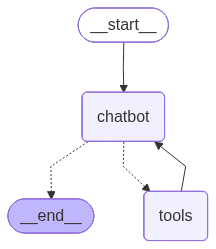

In [4]:
# 웹 검색을 위한 Key 등록
os.environ['TAVILY_API_KEY'] = 'YOUR_TAVILY_API_KEY'

In [5]:
# 상태 정의
class webChatbotState(TypedDict):
    messages : Annotated[list, add_messages]

In [6]:
# llm 모델 생성
llm = init_chat_model(model='gpt-4o-mini', max_tokens=500, temperature=0)

In [7]:
# 검색도구 생성
tool_tavily = TavilySearch(max_results=3)

In [8]:
# 도구를 LLM모델에 바인딩 -> 사용 여부를 LLM이 스스로 결정
llm_with_tools = llm.bind_tools([tool_tavily])

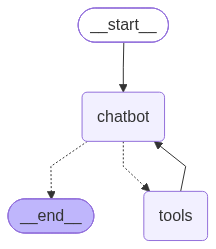

In [9]:
# 그래프 베이스 생성
graph_builder = StateGraph(webChatbotState) # 초기 베이스 생성

# chatbot node 생성
def chatbot(s : webChatbotState) -> webChatbotState:
    response = llm_with_tools.invoke(s['messages']) # LLM 답변 얻기
    return {'messages':[response]} # LLM 응답을 state에 실어서 반환

# chatbot node 추가
graph_builder.add_node('chatbot', chatbot)

# tavily node 생성 및 추가
tool_node = ToolNode([tool_tavily])
graph_builder.add_node('tools', tool_node)

# Edge 연결
graph_builder.add_edge(START, 'chatbot')
graph_builder.add_conditional_edges('chatbot', tools_condition)
graph_builder.add_edge('tools', 'chatbot')

# 컴팜일 및 시각화
graph = graph_builder.compile()
display(Image(graph.get_graph().draw_mermaid_png()))

In [10]:
# 일반 질문 실행
question = '1+1은 뭐야?'
response = graph.invoke({'messages' : [('user', question)]})

In [11]:
response

{'messages': [HumanMessage(content='1+1은 뭐야?', additional_kwargs={}, response_metadata={}, id='3de4ff9e-6f8c-4781-a4e9-5cb2c90bc9ba'),
  AIMessage(content='1 + 1은 2입니다.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 10, 'prompt_tokens': 1194, 'total_tokens': 1204, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_da56f7d23d', 'id': 'chatcmpl-EJTF0NFa21PmASDYDYZuyhkLIcjqC', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a05f8b-085c-7f12-929c-9a2d06f5f614-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 1194, 'output_tokens': 10, 'total_tokens

In [12]:
# 웹서칭이 필요한 질문 실행
question = '광주오늘 날씨 알려줘'
response = graph.invoke({'messages' : [('user', question)]})

In [13]:
response

{'messages': [HumanMessage(content='광주오늘 날씨 알려줘', additional_kwargs={}, response_metadata={}, id='9d1867a4-eefd-4b08-aa7a-0616be601905'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 23, 'prompt_tokens': 1194, 'total_tokens': 1217, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 1152, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_da56f7d23d', 'id': 'chatcmpl-EJTF1AhNgDmkIzUJCyZMuq9Z3CFk4', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a05f8b-0cb7-7a53-955c-ae098f367f10-0', tool_calls=[{'name': 'tavily_search', 'args': {'query': '광주 날씨', 'topic': 'general'}, 'id': 'call_vcBN6q3ZBtF7

### LangGraph기반 Naive RAG 만들기

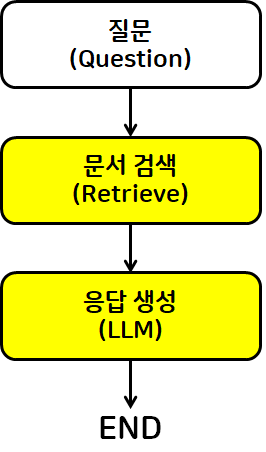

In [35]:
# 상태 정의
class RAGState(TypedDict):
    question: Annotated[str, 'User Question']
    context: Annotated[str, 'Retriever result']
    answer: Annotated[str, 'LLM Answer']
    sources: Annotated[list, 'Source list']   # 추가
    messages: Annotated[list, add_messages]

### 문서로드/청킹/임베딩/벡터DB생성/검색기생성

In [36]:
# 문서로드
loader = PyPDFLoader('data/SPRi AI Brief_11월호산업동향.pdf')
documents = loader.load()

# Chunking 작업 : 작은 단위로 나누는 작업 -> 답변의 품질 향상 및 토큰 비용 절약
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size = 500, # 청크의 크기
    chunk_overlap = 100 # 청크끼리 겹치는 글자 수
)
texts = text_splitter.split_documents(documents) # 청킹작업 실시

# 임베딩 및 벡터DB 저장(글자를 숫자로 변경하는 작업)
vec_db = FAISS.from_documents(
    texts, # 잘라낸 글자 묶음
    OpenAIEmbeddings() # 임베딩 도구
)

# 검색기 생성
retriever = vec_db.as_retriever(search_kwargs={"k": 2})

### 노드생성
- 문서검색노드
- 답변생성노드

In [37]:
# llm 생성
llm = init_chat_model(model = 'gpt-4o-mini', max_tokens = 500, temperature = 0)

In [38]:

def retrieve_node(s: RAGState) -> RAGState:
    docs = retriever.invoke(s['question'])

    chunks, sources = [], []
    for d in docs:
        file_name = os.path.basename(d.metadata.get('source', '알수없음'))
        page = d.metadata.get('page_label') or d.metadata.get('page', 0) + 1
        tag = f'{file_name} p.{page}'
        sources.append(tag)
        # 청크 본문 앞에 출처 꼬리표를 붙여서 LLM이 인용할 수 있게 만든다
        chunks.append(f'[출처: {tag}]\n{d.page_content}')

    return {'context': '\n\n'.join(chunks), 'sources': sources}

In [ ]:
# 답변생성 노드
def llm_answer(s : RAGState) -> RAGState:
    # 프롬포트 설정
    system_prompt = '''
        당신은 유능한 AI동향 검색 어시스턴트입니다.
        아래 <검색결과>에 있는 내용만 근거로 답변하세요. 근거가 없으면 모른다고 답하세요.

        [작성 규칙]
        1. 각 문장 끝에 근거가 된 출처를 [출처: 파일명 p.페이지] 형태로 표기합니다.
        2. 답변 마지막에 "참고 출처:" 항목을 만들어 사용한 출처를 중복 없이 나열합니다.
        3. <검색결과>에 없는 출처는 절대 지어내지 마세요.

        <검색결과>
        {context}
        </검색결과>
    '''
    # 템플릿 생성
    template = ChatPromptTemplate.from_messages([
        ('system', system_prompt),
        MessagesPlaceholder(variable_name='chat_history'),
        ('human', '{input}')
    ])
    # 체인 구성하기
    chain = template | llm | StrOutputParser()
    # 체인 호출하기
    response = chain.invoke({'context' : s['context'], 'input' : s['question']})
    # 생성된 답변 반환
    return {'answer' : response}

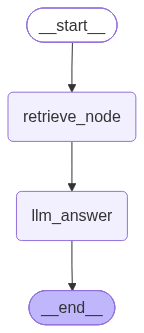

In [40]:
# 그래프 생성
workflow = StateGraph(RAGState) # 그래프 베이스 생성

# 노드 추가
workflow.add_node('retrieve_node', retrieve_node)
workflow.add_node('llm_answer', llm_answer)

# 엣지 추가
workflow.add_edge(START, 'retrieve_node')
workflow.add_edge('retrieve_node', 'llm_answer')
workflow.add_edge('llm_answer', END)

# 컴파일 및 시각화
app = workflow.compile()
display(Image(app.get_graph().draw_mermaid_png()))


In [41]:
# 실행
response = app.invoke(input={'question':'생성형 AI가 개발자들을 대체하는데 어떻게 생각해?'})

In [42]:
response

{'question': '생성형 AI가 개발자들을 대체하는데 어떻게 생각해?',
 'context': '[출처: SPRi AI Brief_11월호산업동향.pdf p.23]\n대체할 가능성이 제한적\n∙ 일례로 생성AI는 디지털 기술 비중이 큰 소프트웨어 개발 직종의 구인 공고에서 통상 제시되는 직무 \n기술의 71%에 대하여 인간을 대체할 가능성이 “보통” 또는 “높음”으로 평가했으나, 간호사 직종의 \n구인 공고에 제시되는 기술의 약 32.9%만 생성AI로 대체될 가능성이 “보통” 또는 “높음”으로 평가  \nn 인디드는 현재 생성AI의 최대 강점은 직무 기술과 관련된 이론적 지식을 제공하는 능력이라고 강조\n∙ 생성AI는 직원 생산성을 극대화하여 노동 시장의 경색을 완화할 수 있으며, 물리적 작업 수행이 필요한 \n직업에서도 근로자가 핵심 업무에 집중할 수 있도록 지원 가능  \n∙ 그러나 생성AI는 논리적 오류나 사실과 다른 내용 또는 편향이나 차별과 같은 비윤리적 응답을 출력할 \n가능성도 있으므로 인간의 신중한 검토 필요\n\n[출처: SPRi AI Brief_11월호산업동향.pdf p.22]\n달리, 가트너는 AI가 향후 소프트웨어 엔지니어의 역할을 변화시키더라도 인간의 전문성과 창의성은 \n여전히 중요하다고 강조\nn 가트너에 따르면 생성AI는 소프트웨어 엔지니어의 역할에 단기, 중기, 장기적으로 영향을 미칠 전망\n∙ 단기적으로는 AI가 기존 개발자의 작업 패턴과 업무를 보완하며 소폭의 생산성 향상 효과를 가져오며, \nAI의 생산성 향상 효과는 성숙한 엔지니어링 관행을 갖춘 기업의 상급 개발자에게 집중될 전망\n∙ 중기적으로는 AI 에이전트를 통해 더 많은 업무가 자동화되어 개발자의 작업 패턴의 변화가 예상되며, \n이는 코드 대부분이 인간이 아닌 AI로 생성되는 AI 네이티브 소프트웨어 엔지니어링의 출현을 의미해 \n자연어 프롬프트 엔지니어링과 검색 증강 생성(RAG)* 기술이 엔지니어링의 필수 역량이 될 전망\n* 외부 데이터를 활용하여 L

### 1. 기본 Navie RAG 실행
### 2. 응답결과에 출처가 표기되도록 변경해보기(실습)
    - 시스템 프로포트 수정
    - 문서검색노드의 Context에 출처정보가 추가되도록 수정

In [43]:
docs = retriever.invoke('생성형 AI가 개발자를 대체할까?')
docs[0].metadata

{'producer': 'Hancom PDF 1.3.0.547',
 'creator': 'Hwp 2018 10.0.0.13947',
 'creationdate': '2024-11-05T15:04:26+09:00',
 'author': 'dj',
 'moddate': '2024-11-05T15:04:26+09:00',
 'pdfversion': '1.4',
 'source': 'data/SPRi AI Brief_11월호산업동향.pdf',
 'total_pages': 25,
 'page': 22,
 'page_label': '23'}

In [44]:
print(response['answer'])
print(response['sources'])          # 실제 검색된 출처
print(response['context'][:500])    # [출처: ...] 꼬리표가 붙었는지 확인

생성형 AI가 개발자들을 대체하는 가능성에 대해서는 다양한 의견이 있습니다. 가트너에 따르면, 생성AI는 소프트웨어 엔지니어의 역할에 단기, 중기, 장기적으로 영향을 미칠 전망입니다. 단기적으로는 AI가 기존 개발자의 작업 패턴과 업무를 보완하며 소폭의 생산성 향상 효과를 가져올 것으로 예상됩니다[출처: SPRi AI Brief_11월호산업동향.pdf p.22]. 중기적으로는 AI 에이전트를 통해 더 많은 업무가 자동화되어 개발자의 작업 패턴이 변화할 것으로 보이며, 이는 AI 네이티브 소프트웨어 엔지니어링의 출현을 의미합니다[출처: SPRi AI Brief_11월호산업동향.pdf p.22].

그러나 생성AI가 모든 직무를 대체할 수 있는 것은 아닙니다. 예를 들어, 생성AI는 디지털 기술 비중이 큰 소프트웨어 개발 직종의 구인 공고에서 통상 제시되는 직무 기술의 71%에 대해 인간을 대체할 가능성이 "보통" 또는 "높음"으로 평가되지만, 간호사 직종의 경우는 약 32.9%만 대체될 가능성이 있다고 합니다[출처: SPRi AI Brief_11월호산업동향.pdf p.23]. 이는 생성AI가 특정 직종에서는 유용할 수 있지만, 모든 직종에서 대체 가능성이 높지 않음을 시사합니다.

결론적으로, 생성형 AI는 개발자들의 역할을 변화시키고 일부 업무를 자동화할 수 있지만, 인간의 전문성과 창의성은 여전히 중요하다는 점을 강조할 필요가 있습니다[출처: SPRi AI Brief_11월호산업동향.pdf p.22].

참고 출처:
- SPRi AI Brief_11월호산업동향.pdf
['SPRi AI Brief_11월호산업동향.pdf p.23', 'SPRi AI Brief_11월호산업동향.pdf p.22']
[출처: SPRi AI Brief_11월호산업동향.pdf p.23]
대체할 가능성이 제한적
∙ 일례로 생성AI는 디지털 기술 비중이 큰 소프트웨어 개발 직종의 구인 공고에서 통상 제시되는 직무 
기술의 71%에 대하여 인간을 대체할 가능성이 “보통” 또는 “높음”으로 평